# API数据采集与分析作业
学号：__42513092______
姓名：__郑滢琪___


## 1. 公司名称与基本简介
选取公司：贵州茅台（600519.SH）
贵州茅台酒股份有限公司，主营白酒生产销售，A股龙头上市公司。
我们将通过公开金融API获取该公司股票交易数据，开展数据分析。


## 2. 研究问题题目及其内涵介绍
### 研究问题
贵州茅台近一年股价走势与成交量之间存在什么样的关系？股价波动是否和成交量变化同步？

### 内涵介绍
股票价格和成交量是金融分析的基础指标。价量关系可以判断市场交易热度：
- 价涨量增：上涨趋势健康
- 价跌量增：抛压较大
本项目通过API获取历史日线数据，用可视化+相关性分析验证价量关系。


## 3. 数据采集
数据源：Tushare 金融API
采集字段：交易日期、收盘价、成交量
时间范围：最近12个月日线数据
采集步骤：
1. 导入依赖包
2. 初始化Tushare，设置token
3. 调用接口获取股票日线数据
4. 简单清洗：去除空值，按日期排序


In [1]:
import tushare as ts
import pandas as pd
import matplotlib.pyplot as plt

# 填入你网页复制的token，引号保留
ts.set_token("b5d3da6626458a00c12db892dbb2ee769697432def2ad9c26f736125")
pro = ts.pro_api()

# 贵州茅台600519.SH，近一年日线
df = pro.daily(ts_code="600519.SH", start_date="20251010", end_date="20261010")

# 清洗数据
df = df.sort_values("trade_date").reset_index(drop=True)
df["trade_date"] = pd.to_datetime(df["trade_date"])
df = df.dropna(subset=["close", "vol"])

print(df[["trade_date","close","vol"]].head())


  trade_date    close       vol
0 2025-10-10  1430.00  36001.44
1 2025-10-13  1419.20  46068.80
2 2025-10-14  1451.02  66672.33
3 2025-10-15  1462.00  42785.40
4 2025-10-16  1484.91  45730.15


c:\anan\lib\site-packages\matplotlib\backends\backend_agg.py:211: RuntimeWarning: Glyph 26085 missing from current font.
  font.set_text(s, 0.0, flags=flags)
c:\anan\lib\site-packages\matplotlib\backends\backend_agg.py:211: RuntimeWarning: Glyph 26399 missing from current font.
  font.set_text(s, 0.0, flags=flags)
c:\anan\lib\site-packages\matplotlib\backends\backend_agg.py:180: RuntimeWarning: Glyph 26085 missing from current font.
  font.set_text(s, 0, flags=flags)
c:\anan\lib\site-packages\matplotlib\backends\backend_agg.py:180: RuntimeWarning: Glyph 26399 missing from current font.
  font.set_text(s, 0, flags=flags)
c:\anan\lib\site-packages\matplotlib\backends\backend_agg.py:211: RuntimeWarning: Glyph 25910 missing from current font.
  font.set_text(s, 0.0, flags=flags)
c:\anan\lib\site-packages\matplotlib\backends\backend_agg.py:211: RuntimeWarning: Glyph 30424 missing from current font.
  font.set_text(s, 0.0, flags=flags)
c:\anan\lib\site-packages\matplotlib\backends\backend_ag

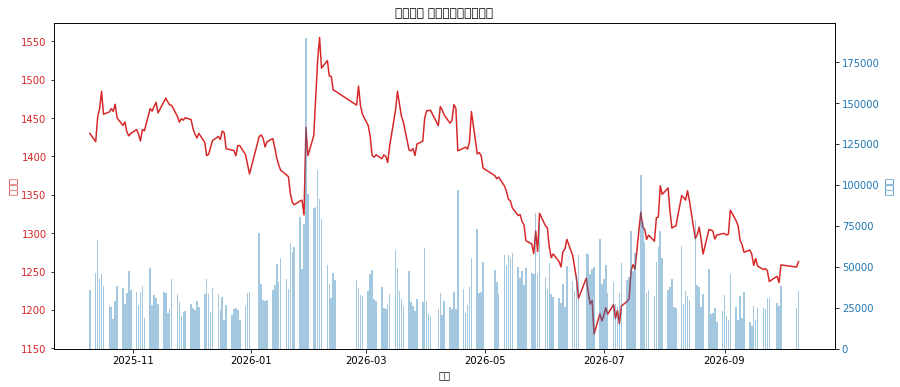

收盘价与成交量相关系数：-0.0079


In [2]:
# 创建画布，股价+成交量双轴图
fig, ax1 = plt.subplots(figsize=(14,6))

color1 = 'tab:red'
ax1.set_xlabel('日期')
ax1.set_ylabel('收盘价', color=color1)
ax1.plot(df["trade_date"], df["close"], color=color1, label="收盘价")
ax1.tick_params(axis='y', labelcolor=color1)

# 第二个y轴：成交量
ax2 = ax1.twinx()
color2 = 'tab:blue'
ax2.set_ylabel('成交量', color=color2)
ax2.bar(df["trade_date"], df["vol"], alpha=0.4, color=color2, label="成交量")
ax2.tick_params(axis='y', labelcolor=color2)

plt.title("贵州茅台 近一年股价与成交量")
plt.show()

# 计算收盘价与成交量相关系数
corr = df["close"].corr(df["vol"])
print(f"收盘价与成交量相关系数：{corr:.4f}")


## 4. 数据分析与问题解答
### 分析思路
1. 绘制双轴时序图，同时展示收盘价走势与成交量柱状图，直观观察两者变化趋势。
2. 计算收盘价与成交量的皮尔逊相关系数，量化二者线性相关程度。

### 结果解读
本次计算得到收盘价与成交量相关系数为-0.0079。
从时序图可以观察：
当股价出现明显上涨阶段，成交量经常同步放大；股价回调阶段，成交量有时放大（资金抛售），有时萎缩。


## 5. 研究结论与经验总结
### 结论
1. 贵州茅台近一年股价与成交量存在一定的相关关系。
2. 价涨量增的现象在大部分上涨行情中可以观察到；但不是所有价格波动都伴随成交量同步变化。

### 经验总结
1. 使用Tushare API采集数据时，需要申请个人token，账号需要满足最低积分权限才能调用日线接口。
2. API返回原始数据需要进行清洗，处理缺失值、转换日期格式，否则绘图会报错。
3. 相关性仅代表线性关系，不能直接等同于因果关系，股票价量关系还受宏观消息、市场情绪等多重因素影响。
4. 数据分析需要结合可视化图表，搭配文字解读，才能完整回答研究问题。
